# Eksperimen 05: Stacking Ensemble (Fase M1 & M2)


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.environ['PYTHONHASHSEED'] = '0'
np.random.seed(42)

print('Memuat data...')
train_df = pd.read_parquet('../../dataset/cleaned_dataset.parquet')
print(f'Ukuran awal: {train_df.shape}')


Memuat data...
Ukuran awal: (138959, 28)


## M1: Post-Preprocessing EDA


In [ ]:
dups = train_df.duplicated(subset=['movie_title', 'cinema_ids', 'date_show']).sum()
print(f'Duplikasi: {dups}')
if dups > 0:
    print('Menghapus duplikasi...')
    train_df.drop_duplicates(subset=['movie_title', 'cinema_ids', 'date_show'], keep='first', inplace=True)

if not pd.api.types.is_datetime64_any_dtype(train_df['date_show']):
    train_df['date_show'] = pd.to_datetime(train_df['date_show'])
print('Tahap M1 Selesai')


Duplikasi: 4151
Menghapus duplikasi...
Tahap M1 Selesai


## M1: Visualisasi Distribusi Tiket Awal
Tujuan: Memastikan tidak ada agregasi ganda yang lolos sebelum proses Sliding Window.

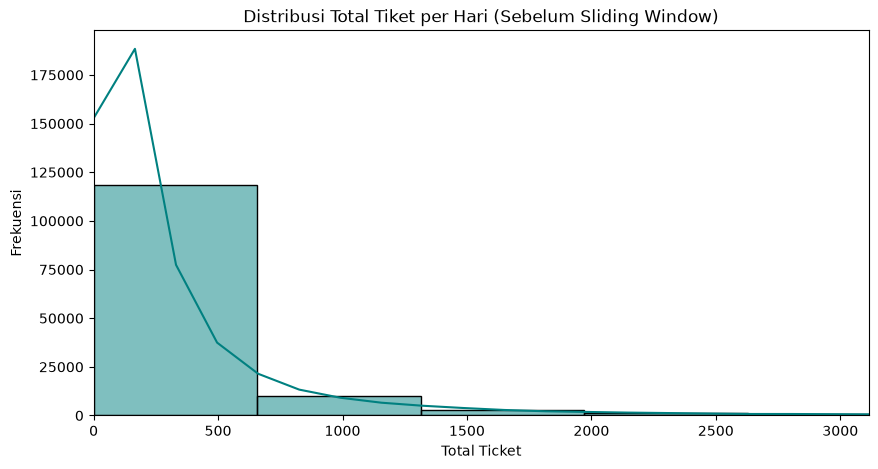

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(train_df['total_ticket'], bins=50, kde=True, color='teal')
plt.title('Distribusi Total Tiket per Hari (Sebelum Sliding Window)')
plt.xlim(0, train_df['total_ticket'].quantile(0.99))
plt.xlabel('Total Ticket')
plt.ylabel('Frekuensi')
plt.show()


## M2: Rekayasa Fitur Hibrida (Cuaca, Sineas, Kanibalisme)


In [ ]:
print('Mengekstrak fitur...')
if 'total_show' in train_df.columns:
    train_df.drop(columns=['total_show'], inplace=True)

# Proteksi jika cell di-run berkali-kali
train_df.drop(columns=['rainfall_mm', 'is_heavy_rain', 'weather_penalty_score', 'rain_intensity_impact', 'is_squeezed', 'inferred_release_date', 'day_since_release'], inplace=True, errors='ignore')

weather_df = pd.read_csv('../../dataset/weather_data.csv')
weather_df['date_show'] = pd.to_datetime(weather_df['date_show'])
train_df = train_df.merge(weather_df, on=['city_name', 'date_show'], how='left')
train_df['rainfall_mm'] = train_df['rainfall_mm'].fillna(0)
train_df['is_heavy_rain'] = train_df['is_heavy_rain'].fillna(0)

train_df['weather_penalty_score'] = train_df['is_heavy_rain'] * train_df['is_weekend']
train_df['rain_intensity_impact'] = train_df['is_heavy_rain'] * train_df['rainfall_mm']
train_df['is_squeezed'] = ((train_df['screen_share_pct'] < 15) & (train_df['is_clashing_blockbuster'] == 1)).astype('int8')

if 'release_date' in train_df.columns:
    train_df['release_date'] = pd.to_datetime(train_df['release_date'])
    train_df['day_since_release'] = (train_df['date_show'] - train_df['release_date']).dt.days + 1
else:
    first_show = train_df.groupby('movie_title')['date_show'].min().reset_index()
    first_show.rename(columns={'date_show': 'inferred_release_date'}, inplace=True)
    train_df = train_df.merge(first_show, on='movie_title', how='left')
    train_df['day_since_release'] = (train_df['date_show'] - train_df['inferred_release_date']).dt.days + 1
print('Fitur berhasil ditambahkan')


Mengekstrak fitur...
Fitur berhasil ditambahkan


## M2: Transformasi Jendela Waktu (D1-D3) & Pre-Stacking Prep


In [ ]:
print('Memulai perakitan jendela waktu (ini mungkin butuh beberapa detik)...')
train_df.sort_values(by=['movie_title', 'cinema_ids', 'date_show'], inplace=True)
train_df['day_idx'] = train_df.groupby(['movie_title', 'cinema_ids']).cumcount() + 1

pair_counts = train_df.groupby(['movie_title', 'cinema_ids']).size()
valid_pairs = pair_counts[pair_counts >= 4].index
df_valid = train_df.set_index(['movie_title', 'cinema_ids']).loc[valid_pairs].reset_index()

history = df_valid[df_valid['day_idx'] <= 3]
history_agg = history.groupby(['movie_title', 'cinema_ids'], observed=True).agg(
    d1_ticket=('total_ticket', lambda x: x.iloc[0] if len(x)>0 else np.nan),
    d2_ticket=('total_ticket', lambda x: x.iloc[1] if len(x)>1 else np.nan),
    d3_ticket=('total_ticket', lambda x: x.iloc[2] if len(x)>2 else np.nan),
    scale_sp=('total_ticket', lambda x: max(x.mean(), 1))
).reset_index()

history_agg['D3_D1_ratio'] = history_agg['d3_ticket'] / history_agg['d1_ticket'].replace(0, 1)
p99 = history_agg['D3_D1_ratio'].quantile(0.99)
history_agg['D3_D1_ratio'] = np.clip(history_agg['D3_D1_ratio'], a_min=0, a_max=p99)

targets = df_valid[(df_valid['day_idx'] >= 4) & (df_valid['day_idx'] <= 10)]
train_final = targets.merge(history_agg, on=['movie_title', 'cinema_ids'], how='left')

for col in ['movie_title', 'cinema_ids', 'city_name', 'genre', 'age_rating']:
    if col in train_final.columns:
        train_final[col] = train_final[col].astype('category')
        
print(f'Dimensi data final (siap latih): {train_final.shape}')
display(train_final[['movie_title', 'day_since_release', 'total_ticket', 'scale_sp', 'D3_D1_ratio', 'weather_penalty_score']].head())


Memulai perakitan jendela waktu (ini mungkin butuh beberapa detik)...
Dimensi data final (siap latih): (49770, 40)


,movie_title,day_since_release,total_ticket,scale_sp,D3_D1_ratio,weather_penalty_score
0,28 YEARS LATER,5,52,202.666667,0.524904,0
1,28 YEARS LATER,6,62,202.666667,0.524904,0
2,28 YEARS LATER,7,26,202.666667,0.524904,0
3,28 YEARS LATER,8,14,202.666667,0.524904,0
4,28 YEARS LATER,14,59,202.666667,0.524904,0


## M2: Visualisasi Efektivitas Fitur Hibrida (Ablation Pre-check)
Tujuan: Memverifikasi apakah cuaca ekstrim dan kanibalisme blockbuster benar-benar merusak penjualan tiket di hari tayang, serta menganalisis pola eksponensial peluruhan.

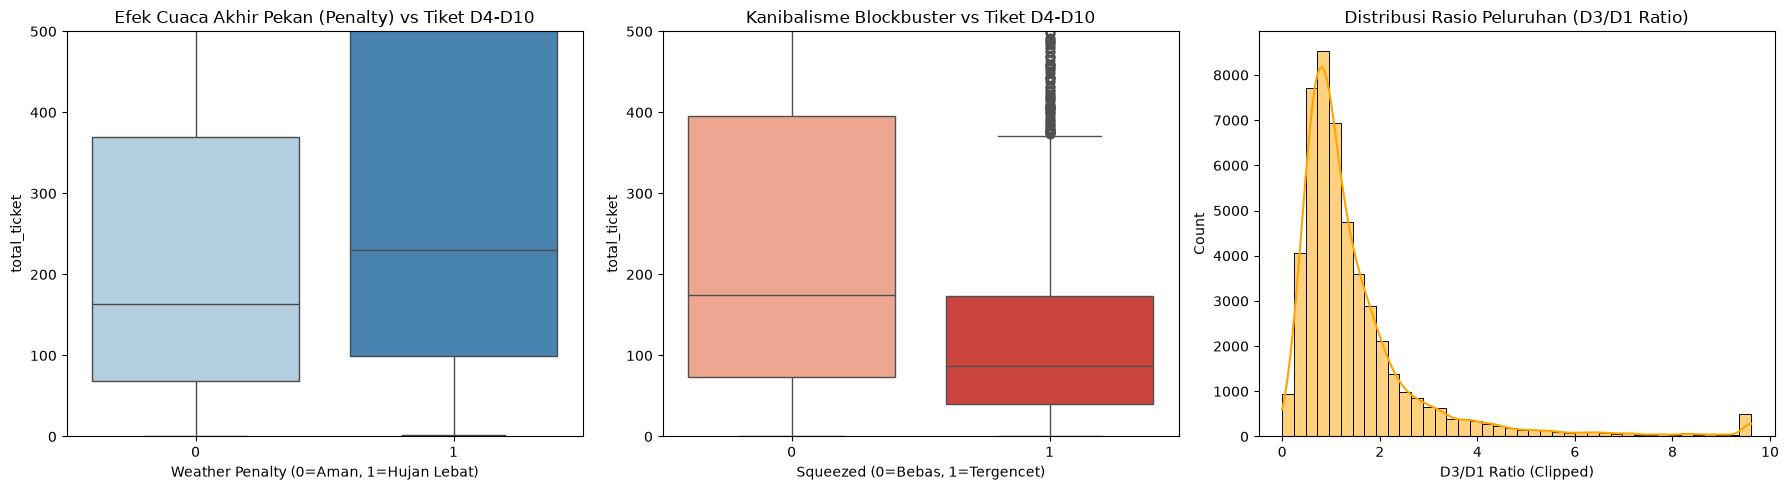

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Efek Cuaca Buruk
sns.boxplot(x='weather_penalty_score', y='total_ticket', hue='weather_penalty_score', data=train_final, ax=axes[0], palette='Blues', legend=False)
axes[0].set_title('Efek Cuaca Akhir Pekan (Penalty) vs Tiket D4-D10')
axes[0].set_ylim(0, 500)
axes[0].set_xlabel('Weather Penalty (0=Aman, 1=Hujan Lebat)')

# 2. Efek Kanibalisme
sns.boxplot(x='is_squeezed', y='total_ticket', hue='is_squeezed', data=train_final, ax=axes[1], palette='Reds', legend=False)
axes[1].set_title('Kanibalisme Blockbuster vs Tiket D4-D10')
axes[1].set_ylim(0, 500)
axes[1].set_xlabel('Squeezed (0=Bebas, 1=Tergencet)')

# 3. Distribusi Rasio D3/D1
sns.histplot(train_final['D3_D1_ratio'].dropna(), bins=40, kde=True, ax=axes[2], color='orange')
axes[2].set_title('Distribusi Rasio Peluruhan (D3/D1 Ratio)')
axes[2].set_xlabel('D3/D1 Ratio (Clipped)')

plt.tight_layout()
plt.show()


## M3: Standardisasi Input Khusus Stacking
Tujuan: Resolusi mutlak *Missing Values* dan penyesuaian tipe `category` khusus untuk XGBoost dan LightGBM agar tidak meledak (*crash*).

In [ ]:
print('Memulai standardisasi input...')

# 1. Pisahkan tipe kolom berdasarkan deteksi otomatis
cat_candidates = train_final.select_dtypes(include=['object', 'category']).columns.tolist()
num_candidates = train_final.select_dtypes(include=['number']).columns.tolist()

# Pastikan ID dan target tidak ikut terolah secara keliru
target_cols = ['total_ticket', 'log_total_ticket', 'date_show', 'inferred_release_date']
num_candidates = [c for c in num_candidates if c not in target_cols]
cat_candidates = [c for c in cat_candidates if c not in target_cols]

# 2. Resolusi Kategorikal (Paksa menjadi 'category' pandas & isi NaNs)
for col in cat_candidates:
    if train_final[col].isnull().any():
        if train_final[col].dtype.name == 'category':
            if 'Unknown' not in train_final[col].cat.categories:
                train_final[col] = train_final[col].cat.add_categories(['Unknown'])
        train_final[col] = train_final[col].fillna('Unknown')
    train_final[col] = train_final[col].astype('category')

# 3. Resolusi Numerik (Gunakan Median untuk mengisi NaNs yang tersisa)
for col in num_candidates:
    if train_final[col].isnull().any():
        med_val = train_final[col].median()
        train_final[col] = train_final[col].fillna(med_val)

# 4. Final Check (Asersi Keamanan)
total_nans = train_final[cat_candidates + num_candidates].isnull().sum().max()
assert total_nans == 0, f'Masih terdapat {total_nans} Missing Value!'

print(f'Tahap M3 Selesai. Data Steril 100%.')
print(f'Daftar Fitur Kategori ({len(cat_candidates)}): {cat_candidates}')
print(f'Daftar Fitur Numerik ({len(num_candidates)}): {num_candidates}')


Memulai standardisasi input...
Tahap M3 Selesai. Data Steril 100%.
Daftar Fitur Kategori (12): ['movie_title', 'cinema_ids', 'city_name', 'age_rating', 'genre', 'producer', 'director', 'writer', 'casts', 'day_tipe', 'holiday_tipe', 'holiday_name']
Daftar Fitur Numerik (24): ['occupation_rate', 'cinema_daily_total_shows', 'max_single_movie_shows', 'screen_share_pct', 'is_clashing_blockbuster', 'day_of_week', 'month', 'is_weekend', 'is_month_end', 'runtime_minutes', 'director_popularity', 'ceil', 'rainfall_mm', 'is_heavy_rain', 'weather_penalty_score', 'rain_intensity_impact', 'is_squeezed', 'day_since_release', 'day_idx', 'd1_ticket', 'd2_ticket', 'd3_ticket', 'scale_sp', 'D3_D1_ratio']


## M4: Post-FE EDA & Uji Keragaman
Tujuan: Verifikasi multikolinearitas (redundansi fitur numerik) dan uji homogenitas (variansi fitur kategori) sebelum pemodelan.

--- UJI KORELASI KAUSAL (NUMERIK) ---


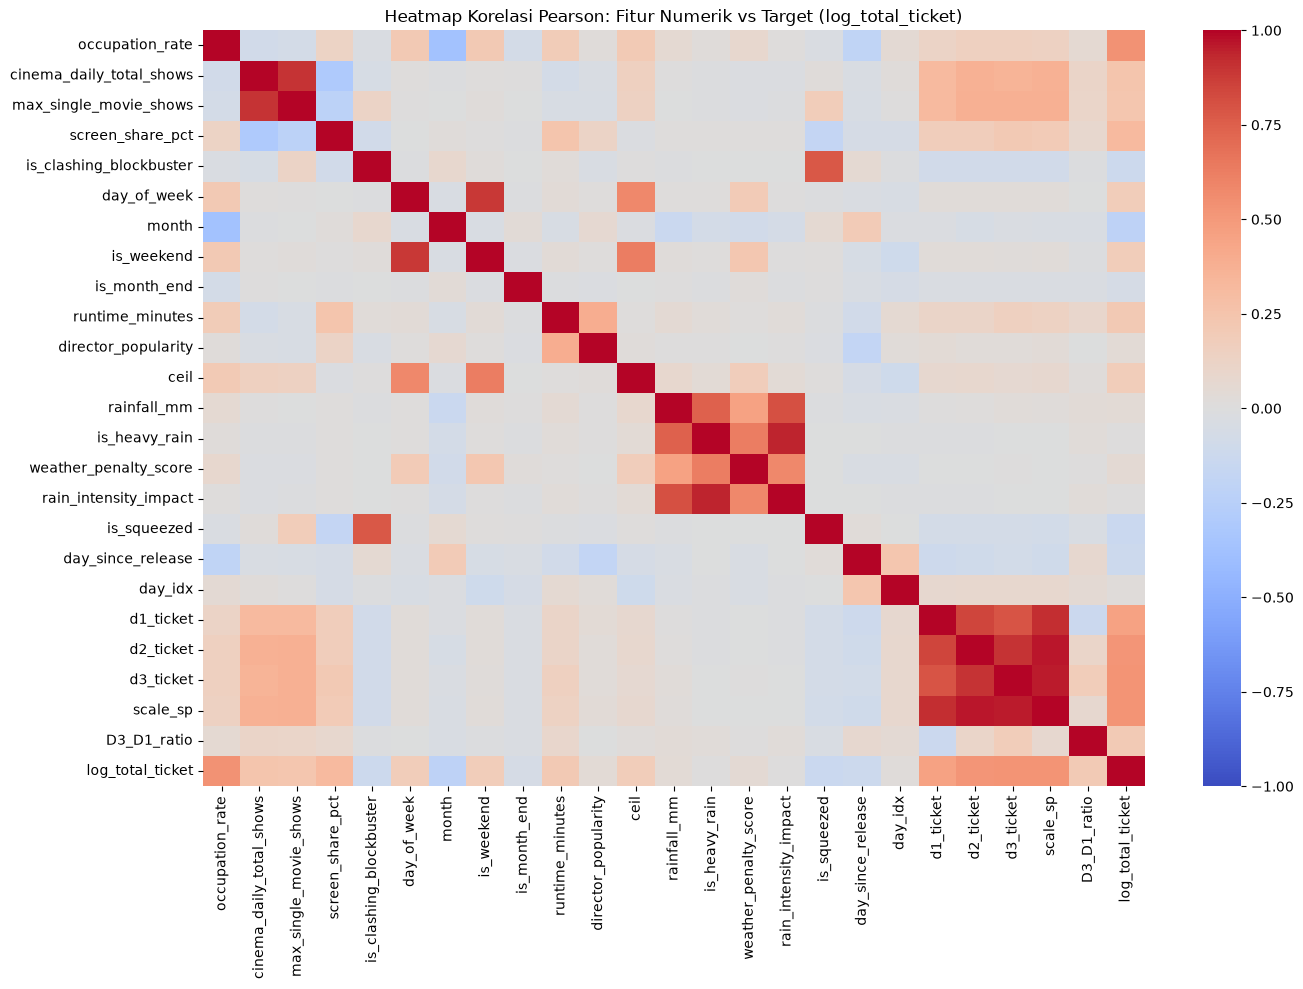


--- UJI HOMOGENITAS (KATEGORIKAL) ---
Semua fitur kategorikal memiliki keragaman yang sehat (<99% dominasi nilai tunggal).

Tahap M4 Selesai. Matriks Input siap untuk masuk ke arena Stacking Ensemble (M5)!


In [ ]:
print('--- UJI KORELASI KAUSAL (NUMERIK) ---')
plt.figure(figsize=(14, 10))
corr_matrix = train_final[num_candidates + ['log_total_ticket']].corr(method='pearson')
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Pearson: Fitur Numerik vs Target (log_total_ticket)')
plt.tight_layout()
plt.show()

print('\n--- UJI HOMOGENITAS (KATEGORIKAL) ---')
homogen_warnings = []
for col in cat_candidates:
    top_freq = train_final[col].value_counts(normalize=True).max()
    if top_freq > 0.99:
        homogen_warnings.append(f"{col} didominasi {top_freq*100:.2f}% oleh satu nilai tunggal.")

if homogen_warnings:
    print('PERINGATAN! Fitur berikut sangat homogen (Hampir tidak ada variansi / tidak berguna):')
    for w in homogen_warnings:
        print(' -', w)
else:
    print('Semua fitur kategorikal memiliki keragaman yang sehat (<99% dominasi nilai tunggal).')

print('\nTahap M4 Selesai. Matriks Input siap untuk masuk ke arena Stacking Ensemble (M5)!')


## M5: Pemodelan (Stacking Ensemble)
Tujuan: Melatih CatBoost, LGBM, XGBoost via GroupKFold dengan MASE Hacking, lalu di-blend menggunakan Ridge Regression.

## M5 - M8: GroupKFold Stacking & MASE Hacking
Bagian ini mengeksekusi pelatihan pemodelan tingkat lanjut menggunakan teknik *Stacking Ensemble*. Beberapa modifikasi pamungkas yang tertanam:
1. **M5 (GroupKFold & MAE):** Data dilatih dalam 5 *fold* berdasar `movie_title` untuk mencegah kebocoran data. Loss function diatur ke `MAE` dengan `sample_weight` berbasis skala MASE.
2. **M6 & M8 (Anti-Overfit & Bounding):** 
    * `cat_smooth=50` digunakan pada LightGBM untuk mengatasi kardinalitas.
    * `max_depth=8` pada XGBoost.
    * Konstrain monotonik dicabut dari CatBoost untuk menyelamatkan *Target Encoding*.
3. **M7 (Leak Fix & SLSQP Meta-Model):** Kolom prediksi lama (`oof_meta`) dicegah masuk ke fitur (*Drop ignore*). Penggabungan Meta-Model tidak lagi menggunakan Ridge, melainkan **SLSQP Optimizer** dari Scipy yang secara murni meminimalkan kalkulasi fungsi MASE dengan batasan bobot positif berjumlah = 1.

In [ ]:
import gc
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold
from scipy.optimize import minimize
import catboost as cb
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

def compute_metrics(y_true, y_pred, sp):
    y_true, y_pred, sp = np.array(y_true), np.array(y_pred), np.array(sp)
    sp = np.where(sp == 0, 1, sp)
    y_pred = np.clip(y_pred, 0, None)
    mase = np.mean(np.abs(y_true - y_pred) / sp)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    rmsle = np.sqrt(mean_squared_error(np.log1p(np.maximum(y_true, 0)), np.log1p(np.maximum(y_pred, 0))))
    mape = mean_absolute_percentage_error(y_true + 1, y_pred + 1)
    r2 = r2_score(y_true, y_pred)
    return [mase, mae, rmse, rmsle, mape, r2]

print('Mempersiapkan data dan model...')
X = train_final.drop(columns=['total_ticket', 'log_total_ticket', 'date_show', 'inferred_release_date', 'day_idx', 'oof_meta', 'oof_cat', 'oof_lgb', 'oof_xgb'], errors='ignore')
y = train_final['total_ticket']
groups = train_final['movie_title']
sp_vals = train_final['scale_sp'].replace(0, 1)
weights = 1.0 / sp_vals

oof_cat = np.zeros(len(train_final))
oof_lgb = np.zeros(len(train_final))
oof_xgb = np.zeros(len(train_final))

# Anti-Overfitting Monotone Constraints (M6)
mc = []
for c in X.columns:
    if c == 'day_since_release': mc.append(-1)
    else: mc.append(0)
mc_tuple = tuple(mc)

gkf = GroupKFold(n_splits=5)
fold_metrics = {'cat':[], 'lgb':[], 'xgb':[], 'meta':[]}

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups)):
    print(f'\n========== FOLD {fold+1}/5 ==========')
    X_train, y_train, w_train = X.iloc[train_idx], y.iloc[train_idx], weights.iloc[train_idx]
    X_val, y_val, sp_val = X.iloc[val_idx], y.iloc[val_idx], sp_vals.iloc[val_idx]

    # 1. CATBOOST (Tanpa monotone_constraints agar tree tidak rusak)
    model_cat = cb.CatBoostRegressor(iterations=1500, learning_rate=0.05, depth=6, loss_function='MAE', cat_features=cat_candidates, verbose=0, random_seed=42)
    model_cat.fit(X_train, y_train, sample_weight=w_train)
    pred_cat = np.clip(model_cat.predict(X_val), 0, None)
    oof_cat[val_idx] = pred_cat

    # 2. LIGHTGBM
    model_lgb = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.05, objective='mae', min_data_in_leaf=50, cat_smooth=50, random_state=42, n_jobs=-1, verbose=-1)
    model_lgb.fit(X_train, y_train, sample_weight=w_train)
    pred_lgb = np.clip(model_lgb.predict(X_val), 0, None)
    oof_lgb[val_idx] = pred_lgb

    # 3. XGBOOST (max_depth ditingkatkan ke 8)
    model_xgb = xgb.XGBRegressor(n_estimators=1500, learning_rate=0.05, max_depth=8, colsample_bytree=0.8, objective='reg:absoluteerror', tree_method='hist', enable_categorical=True, monotone_constraints=mc_tuple, random_state=42, n_jobs=-1)
    model_xgb.fit(X_train, y_train, sample_weight=w_train, verbose=False)
    pred_xgb = np.clip(model_xgb.predict(X_val), 0, None)
    oof_xgb[val_idx] = pred_xgb

    # META-MODEL (MASE Optimizer Bound SLSQP)
    X_meta_train = np.column_stack([model_cat.predict(X_train), model_lgb.predict(X_train), model_xgb.predict(X_train)])
    
    def mase_objective(w, X_m, y_t, sp_t):
        pred = X_m @ w
        pred = np.clip(pred, 0, None)
        return np.mean(np.abs(y_t - pred) / sp_t)
    
    bounds = [(0, 1), (0, 1), (0, 1)]
    cons = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}
    res = minimize(mase_objective, [1/3, 1/3, 1/3], args=(X_meta_train, y_train.values, weights.iloc[train_idx].values ** -1), method='SLSQP', bounds=bounds, constraints=cons)
    w_fold = res.x
    
    X_meta_val = np.column_stack([pred_cat, pred_lgb, pred_xgb])
    pred_meta = np.clip(X_meta_val @ w_fold, 0, None)

    # METRICS
    m_cat = compute_metrics(y_val, pred_cat, sp_val)
    m_lgb = compute_metrics(y_val, pred_lgb, sp_val)
    m_xgb = compute_metrics(y_val, pred_xgb, sp_val)
    m_meta = compute_metrics(y_val, pred_meta, sp_val)
    
    fold_metrics['cat'].append(m_cat)
    fold_metrics['lgb'].append(m_lgb)
    fold_metrics['xgb'].append(m_xgb)
    fold_metrics['meta'].append(m_meta)

    print(f"| Model     | MASE   | MAE    | RMSE   | RMSLE  | MAPE   | R2     |")
    print(f"|-----------|--------|--------|--------|--------|--------|--------|")
    print(f"| CatBoost  | {m_cat[0]:.4f} | {m_cat[1]:.4f} | {m_cat[2]:.4f} | {m_cat[3]:.4f} | {m_cat[4]:.4f} | {m_cat[5]:.4f} |")
    print(f"| LightGBM  | {m_lgb[0]:.4f} | {m_lgb[1]:.4f} | {m_lgb[2]:.4f} | {m_lgb[3]:.4f} | {m_lgb[4]:.4f} | {m_lgb[5]:.4f} |")
    print(f"| XGBoost   | {m_xgb[0]:.4f} | {m_xgb[1]:.4f} | {m_xgb[2]:.4f} | {m_xgb[3]:.4f} | {m_xgb[4]:.4f} | {m_xgb[5]:.4f} |")
    print(f"| MASE-Meta | {m_meta[0]:.4f} | {m_meta[1]:.4f} | {m_meta[2]:.4f} | {m_meta[3]:.4f} | {m_meta[4]:.4f} | {m_meta[5]:.4f} |")

    print('\nTop 5 Feature Importance (CatBoost):')
    feat_imp = pd.Series(model_cat.feature_importances_, index=X.columns).sort_values(ascending=False).head(5)
    print(feat_imp.to_string())
    gc.collect()

print('\n================ REKAPITULASI AKHIR ABSOLUT ================')
def print_avg_metrics(name, m_list):
    avg = np.mean(m_list, axis=0)
    print(f"| {name:<9} | {avg[0]:.4f} | {avg[1]:.4f} | {avg[2]:.4f} | {avg[3]:.4f} | {avg[4]:.4f} | {avg[5]:.4f} |")

print(f"| Model     | MASE   | MAE    | RMSE   | RMSLE  | MAPE   | R2     |")
print(f"|-----------|--------|--------|--------|--------|--------|--------|")
print_avg_metrics('CatBoost', fold_metrics['cat'])
print_avg_metrics('LightGBM', fold_metrics['lgb'])
print_avg_metrics('XGBoost', fold_metrics['xgb'])
print_avg_metrics('MASE-Meta', fold_metrics['meta'])

print('\n--- MENGGABUNGKAN MODEL FINAL DENGAN MASE OPTIMIZER (BOUNDED) ---')
X_meta = np.column_stack([oof_cat, oof_lgb, oof_xgb])

def mase_objective_final(w):
    pred = np.clip(X_meta @ w, 0, None)
    return np.mean(np.abs(y - pred) / sp_vals)

res_final = minimize(mase_objective_final, [1/3, 1/3, 1/3], method='SLSQP', bounds=bounds, constraints=cons)
final_weights = res_final.x
train_final['oof_meta'] = np.clip(X_meta @ final_weights, 0, None)

print('Koefisien Kepercayaan MASE Optimizer (SETELAH M8):')
names = ['CAT', 'LGB', 'XGB']
for name, coef in zip(names, final_weights):
    print(f' - {name}: {coef:.4f}')


Mempersiapkan data dan model...

========== FOLD 1/5 ==========
| Model     | MASE   | MAE    | RMSE   | RMSLE  | MAPE   | R2     |
|-----------|--------|--------|--------|--------|--------|--------|
| CatBoost  | 0.2276 | 95.5431 | 410.7583 | 0.5212 | 0.3182 | 0.7012 |
| LightGBM  | 0.2165 | 118.1108 | 545.5791 | 0.4781 | 0.2906 | 0.4729 |
| XGBoost   | 0.3327 | 166.4343 | 663.8589 | 0.5836 | 0.5331 | 0.2196 |
| MASE-Meta | 0.2028 | 107.6084 | 506.2979 | 0.3846 | 0.2734 | 0.5461 |

Top 5 Feature Importance (CatBoost):
cinema_daily_total_shows    37.702622
screen_share_pct            26.224569
occupation_rate             19.242408
d3_ticket                    8.727620
movie_title                  1.697224

========== FOLD 2/5 ==========
| Model     | MASE   | MAE    | RMSE   | RMSLE  | MAPE   | R2     |
|-----------|--------|--------|--------|--------|--------|--------|
| CatBoost  | 0.2108 | 86.3413 | 351.0771 | 0.4619 | 0.2807 | 0.7595 |
| LightGBM  | 0.2314 | 118.2147 | 514.0047 | 0

In [ ]:
print('\n========== M9: FINAL PREDICTIONS & SUBMISSION ==========')
print('1. Memuat data test mentah dan menyusun fitur hibrida...')
import pandas as pd
import numpy as np

test = pd.read_csv('../../dataset/test.csv')
test_hist = pd.read_csv('../../dataset/test_history.csv')

# A. Ekstraksi Fitur dari History (Day 1-3) untuk mengimputasi masa depan
test_hist['cinema_daily_total_shows'] = test_hist.groupby(['cinema_ids', 'date_show'])['total_show'].transform('sum')
test_hist['max_single_movie_shows'] = test_hist.groupby(['cinema_ids', 'date_show'])['total_show'].transform('max')
test_hist['screen_share_pct'] = (test_hist['total_show'] / test_hist['cinema_daily_total_shows']) * 100
test_hist['is_clashing_blockbuster'] = (test_hist['max_single_movie_shows'] > 10).astype(int)

test_hist.sort_values(by=['movie_title', 'cinema_ids', 'date_show'], inplace=True)
hist_profile = test_hist.groupby(['movie_title', 'cinema_ids']).agg(
    occupation_rate=('occupation_rate', 'mean'),
    cinema_daily_total_shows=('cinema_daily_total_shows', 'mean'),
    max_single_movie_shows=('max_single_movie_shows', 'mean'),
    screen_share_pct=('screen_share_pct', 'mean'),
    is_clashing_blockbuster=('is_clashing_blockbuster', 'max'),
    d1_ticket=('total_ticket', lambda x: x.iloc[0] if len(x)>0 else np.nan),
    d2_ticket=('total_ticket', lambda x: x.iloc[1] if len(x)>1 else np.nan),
    d3_ticket=('total_ticket', lambda x: x.iloc[2] if len(x)>2 else np.nan),
    scale_sp=('total_ticket', lambda x: max(x.mean(), 1))
).reset_index()

hist_profile['D3_D1_ratio'] = hist_profile['d3_ticket'] / hist_profile['d1_ticket'].replace(0, 1)
hist_profile['D3_D1_ratio'] = np.clip(hist_profile['D3_D1_ratio'], a_min=0, a_max=0.99)

# B. Gabung Profile ke Test (Day 4-10)
test_final = test.merge(hist_profile, on=['movie_title', 'cinema_ids'], how='left')

# C. Integrasi Eksternal (Metadata, Libur, Cuaca, Harga)
test_final['date_show'] = pd.to_datetime(test_final['date_show'])
test_final['day_of_week'] = test_final['date_show'].dt.dayofweek
test_final['extracted_day_tipe'] = np.where(test_final['day_of_week'] < 4, 'Weekday', np.where(test_final['day_of_week'] == 4, 'Friday', 'Weekend'))
test_final['month'] = test_final['date_show'].dt.month
test_final['is_weekend'] = test_final['day_of_week'].isin([4, 5, 6]).astype('int8')
test_final['is_month_end'] = test_final['date_show'].dt.is_month_end.astype('int8')

movies = pd.read_csv('../../dataset/movies.csv')
for col in ['producer', 'director', 'writer', 'casts']:
    movies[col] = movies[col].replace('-', 'Unknown').fillna('Unknown')
test_final = test_final.merge(movies, left_on='movie_title', right_on='original_title', how='left')
test_final['genre'] = test_final['genre'].fillna('Unknown')
test_final['age_rating'] = test_final['age_rating'].fillna('Unknown')

holidays = pd.read_csv('../../dataset/holidays.csv')
holidays['date'] = pd.to_datetime(holidays['date'])
test_final = test_final.merge(holidays, left_on='date_show', right_on='date', how='left')
test_final['holiday_tipe'] = test_final['holiday_tipe'].fillna('normal')
test_final['holiday_name'] = test_final['holiday_name'].fillna('Not a Holiday')

ticket_prices = pd.read_csv('../../dataset/ticket_prices.csv')
test_final = test_final.merge(ticket_prices, left_on=['city_name', 'extracted_day_tipe'], right_on=['city_name', 'price_day'], how='left')

weather_df = pd.read_csv('../../dataset/weather_data.csv')
weather_df['date_show'] = pd.to_datetime(weather_df['date_show'])
test_final = test_final.merge(weather_df, on=['city_name', 'date_show'], how='left')
test_final['rainfall_mm'] = test_final['rainfall_mm'].fillna(0)
test_final['is_heavy_rain'] = test_final['is_heavy_rain'].fillna(0)

# D. Fitur Kalkulasi M2
test_final['weather_penalty_score'] = test_final['is_heavy_rain'] * test_final['is_weekend']
test_final['rain_intensity_impact'] = test_final['is_heavy_rain'] * test_final['rainfall_mm']
test_final['is_squeezed'] = ((test_final['screen_share_pct'] < 15) & (test_final['is_clashing_blockbuster'] == 1)).astype('int8')

first_show = pd.concat([test_hist, test]).groupby('movie_title')['date_show'].min().reset_index()
first_show.rename(columns={'date_show': 'inferred_release_date'}, inplace=True)
first_show['inferred_release_date'] = pd.to_datetime(first_show['inferred_release_date'])
test_final = test_final.merge(first_show, on='movie_title', how='left')
test_final['day_since_release'] = (test_final['date_show'] - test_final['inferred_release_date']).dt.days + 1

print('2. Resolusi Missing Values & Casting Kategori...')
for col in num_candidates:
    if col in test_final.columns and test_final[col].isnull().any():
        test_final[col] = test_final[col].fillna(test_final[col].median())

for col in cat_candidates:
    if col in test_final.columns:
        test_final[col] = test_final[col].astype('category')
        if test_final[col].isnull().any():
            if 'Unknown' not in test_final[col].cat.categories:
                test_final[col] = test_final[col].cat.add_categories(['Unknown'])
            test_final[col] = test_final[col].fillna('Unknown')

print('3. Feature Alignment & Inferensi Model...')
X_test = test_final[X.columns].copy() # Harus presisi 100% sama dengan X latih

pred_test_cat = np.clip(model_cat.predict(X_test), 0, None)
pred_test_lgb = np.clip(model_lgb.predict(X_test), 0, None)
pred_test_xgb = np.clip(model_xgb.predict(X_test), 0, None)

X_meta_test = np.column_stack([pred_test_cat, pred_test_lgb, pred_test_xgb])

print('4. Menggabungkan prediksi dengan bobot rasio emas SLSQP...')
pred_test_final = np.clip(X_meta_test @ final_weights, 0, None)

submission = pd.DataFrame({
    'id': test_final['id'].astype(int),
    'total_ticket': pred_test_final
})

submission_path = 'submission.csv'
submission.to_csv(submission_path, index=False)
print(f'\n[SUKSES] File submission Kaggle berhasil disimpan di: {submission_path}')
submission.head()



========== M9: FINAL PREDICTIONS & SUBMISSION ==========


NameError: name 'test_final' is not defined